# 02 · Synthetic Data Generation and Validation
**Milestone 1 — Kenyan Retail Customer & Sales Intelligence Capstone**

This notebook explains **how** the Duka Bora dataset was generated, runs the generator, and checks that:
1. the raw sales file has **exactly 3,000 rows**;
2. the data is **reproducible** (same seed, same data);
3. the intended **business patterns** are really present;
4. the injected **data-quality issues** are present and logged, ready for Milestone 2.

The generator code lives in `src/data_generation/` so it can be tested and reused. This notebook only *calls* it.

## 1. Design principles

| Principle | How it is implemented |
|---|---|
| **Business logic, not random numbers** | Daily shopping intensity combines month seasonality, weekday, payday window (25th–3rd), holiday eves, promotions and slow growth. Orders are placed on days in proportion to that intensity |
| **Different customer behaviours** | Four *hidden* segments: one-off (78%), occasional, regular and loyal. The segment label is **not exported**, so RFM must rediscover it from behaviour |
| **Customers drifting away** | About one third of regular and loyal customers stop buying after 4–12 months |
| **Products sell at different rates** | Each product has a popularity weight and a typical quantity. Staples are bought in multiples |
| **Stores differ** | Stores differ in traffic share, basket size (Westlands largest) and category mix (Mombasa more beverages, Westlands more electronics) |
| **Promotions change behaviour** | During a campaign, the target category is 1.7× more likely to be bought, in about 30% larger quantities |
| **Realistic payments** | M-Pesa is dominant. Big baskets (KES 10,000+) shift towards card and bank transfer, and small baskets towards cash |
| **Price change** | A 4% shelf-price and cost review on 1 January 2025 |
| **Reproducible** | One NumPy random generator with seed **2024** (data-quality injection uses seed 2025) |

**Pipeline:** calendar → daily intensity → customers & order counts → order dates & stores → basket lines → prices,
discounts, profit → payment method → *inject logged quality issues* → `data/raw/*.csv`

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Run the generator

In [2]:
from src.data_generation.generate_data import generate_clean_dataset, main as generate_raw_files

# Writes all raw CSVs to data/raw/ and the issue log to docs/dq_injection_log.csv
generate_raw_files()

Raw sales rows written: 3,000
  sales_transactions    3,000 rows
  customers             1,800 rows
  products                 40 rows
  stores                    6 rows
  promotions               20 rows
  calendar                731 rows
Injected issues logged: 126 -> docs/dq_injection_log.csv


## 3. Validation checks

In [3]:
import hashlib

raw_sales = pd.read_csv(config.RAW_DIR / "sales_transactions.csv")
print(f"Rows in raw sales file: {len(raw_sales):,}")
assert len(raw_sales) == config.RAW_SALES_ROWS, "Raw sales file must have exactly 3,000 rows"

# Reproducibility: generate the clean data twice and compare a hash of the result.
def fingerprint(df):
    return hashlib.md5(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()

run_1 = generate_clean_dataset()
run_2 = generate_clean_dataset()
print("Run 1 fingerprint:", fingerprint(run_1["sales_transactions"]))
print("Run 2 fingerprint:", fingerprint(run_2["sales_transactions"]))
print("Reproducible:", fingerprint(run_1["sales_transactions"]) == fingerprint(run_2["sales_transactions"]))

Rows in raw sales file: 3,000


Run 1 fingerprint: 26da4ec75128343927676ef9db3198c2
Run 2 fingerprint: 26da4ec75128343927676ef9db3198c2
Reproducible: True


The file has exactly 3,000 rows, and two independent runs produce identical data. Anyone who clones the repository
will get the same numbers as this report.

For the business-pattern checks below we use the **clean** version (before quality issues are injected), so the
checks measure the design rather than the injected errors. Milestone 2 works from the raw files.

In [4]:
clean = run_1
sales = clean["sales_transactions"].copy()
products = clean["products"]
stores = clean["stores"]

sales["transaction_date"] = pd.to_datetime(sales["transaction_date"])
sales = (sales
         .merge(products[["product_id", "product_name", "category"]], on="product_id")
         .merge(stores[["store_id", "town"]], on="store_id"))

orders = sales.groupby("order_id").agg(order_value=("total_amount", "sum"),
                                       lines=("transaction_id", "size"))
summary = pd.Series({
    "Sales lines (clean)": len(sales),
    "Orders": sales["order_id"].nunique(),
    "Customers": sales["customer_id"].nunique(),
    "Net revenue (KES)": sales["total_amount"].sum(),
    "Gross profit (KES)": sales["profit"].sum(),
    "Profit margin": sales["profit"].sum() / sales["total_amount"].sum(),
    "Average order value (KES)": orders["order_value"].mean(),
    "Median order value (KES)": orders["order_value"].median(),
    "Lines per order": orders["lines"].mean(),
    "Promotion lines": sales["promotion_id"].notna().sum(),
})
summary.to_frame("value")

,value
Sales lines (clean),"2,988.00"
Orders,"2,650.00"
Customers,"1,800.00"
Net revenue (KES),"2,179,214.72"
Gross profit (KES),"538,802.12"
Profit margin,0.25
Average order value (KES),822.35
Median order value (KES),450.00
Lines per order,1.13
Promotion lines,315.00


- **2,988 clean lines** form **2,650 orders** from **1,800 customers**.
- The **average order value is about KES 822**, but the **median is only about KES 450**. A few large electronics and clothing baskets pull the mean up, so order values are **right-skewed**. This matters for the choice of statistical tests in Milestone 5.
- The overall gross margin is about **25%**.

### 3.1 Seasonality: are orders higher in December and lower in January?

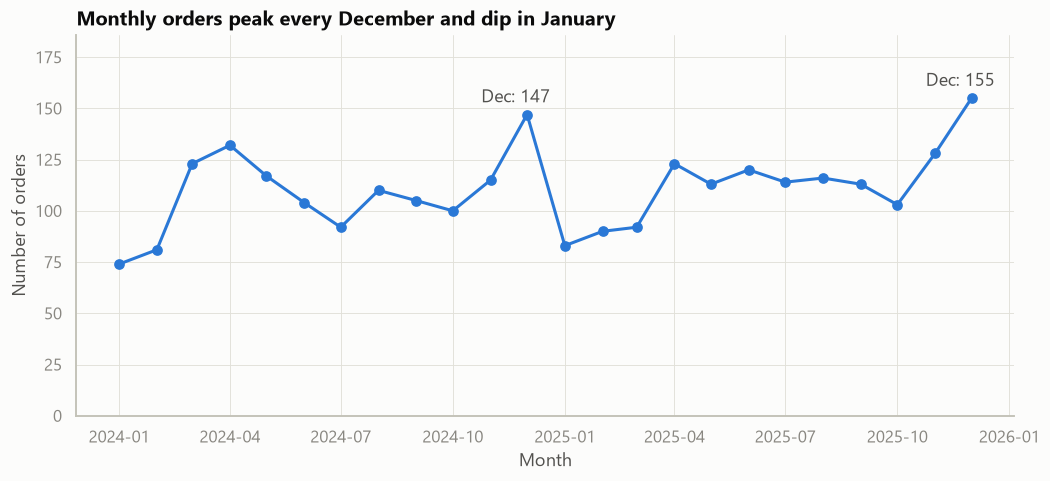

,lines,revenue,revenue_growth,volume_growth
transaction_date,,,,
2024,1467,"1,043,613.60",NaN,NaN
2025,1521,"1,135,601.12",0.09,0.04


In [5]:
monthly_orders = (sales.drop_duplicates("order_id")
                  .set_index("transaction_date").resample("MS").size())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly_orders.index, monthly_orders.values, color=style.HIGHLIGHT, marker="o")
for ts in monthly_orders.index[monthly_orders.index.month == 12]:
    ax.annotate(f"Dec: {monthly_orders[ts]}", (ts, monthly_orders[ts]),
                textcoords="offset points", xytext=(-30, 8), color=style.INK["secondary"])
ax.set_title("Monthly orders peak every December and dip in January")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, monthly_orders.max() * 1.2)
style.save(fig, "m1_monthly_orders")
plt.show()

yearly = sales.groupby(sales["transaction_date"].dt.year).agg(
    lines=("transaction_id", "size"), revenue=("total_amount", "sum"))
yearly["revenue_growth"] = yearly["revenue"].pct_change()
yearly["volume_growth"] = yearly["lines"].pct_change()
yearly

**Interpretation:** orders peak in **December** in both years and fall sharply in **January**, when households
recover from festive spending and pay school fees. Between 2024 and 2025, line volume grew by about 4% while revenue
grew by about 9%. The gap is the 4% price review from 1 January 2025 plus product-mix effects.

**Business implication:** the data supports separating *price* growth from *volume* growth. Without that split,
management might mistake price increases for more customers. Stock and staffing should ramp up from November.

### 3.2 Do categories differ in revenue and margin?

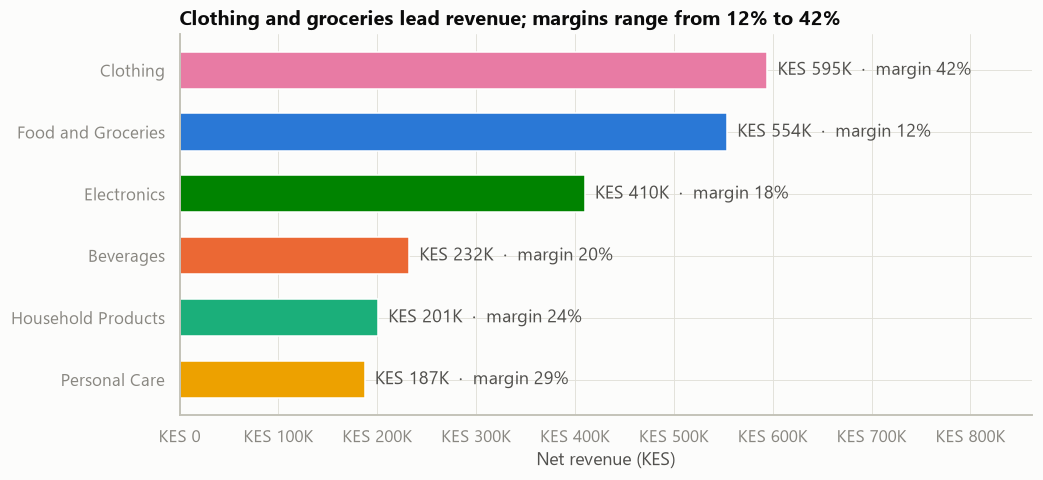

,lines,units,revenue,profit,margin
category,,,,,
Clothing,301,390,"594,639.30","249,530.50",0.42
Food and Groceries,1106,2010,"553,940.20","64,853.12",0.12
Electronics,104,106,"409,970.60","75,492.60",0.18
Beverages,673,1235,"232,359.78","47,614.26",0.20
Household Products,449,579,"200,929.00","47,825.80",0.24
Personal Care,355,459,"187,375.84","53,485.84",0.29


In [6]:
cat = (sales.groupby("category")
       .agg(lines=("transaction_id", "size"), units=("quantity", "sum"),
            revenue=("total_amount", "sum"), profit=("profit", "sum"))
       .sort_values("revenue"))
cat["margin"] = cat["profit"] / cat["revenue"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(cat.index, cat["revenue"], color=[style.CATEGORY_COLORS[c] for c in cat.index], height=0.6)
for y, (rev, m) in enumerate(zip(cat["revenue"], cat["margin"])):
    ax.text(rev, y, f"  {style.kes(rev)}  ·  margin {m:.0%}", va="center", color=style.INK["secondary"])
ax.xaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_xlim(0, cat["revenue"].max() * 1.45)
ax.set_title("Clothing and groceries lead revenue; margins range from 12% to 42%")
ax.set_xlabel("Net revenue (KES)")
ax.set_ylabel("")
style.save(fig, "m1_category_revenue")
plt.show()
cat.sort_values("revenue", ascending=False)

**Interpretation:** Food and Groceries has the most lines (about 1,100) but thin margins (about 12%).
Clothing has far fewer lines but the highest revenue and a margin of about 42%. Electronics sells only about 100 units,
yet brings in almost a fifth of revenue at an 18% margin.

**Business implication:** this matches the margin design (staples are thin, clothing is wide). It also shows why
Milestone 3 must rank products by **profit** as well as revenue, because the two rankings will differ.

### 3.3 Payment methods

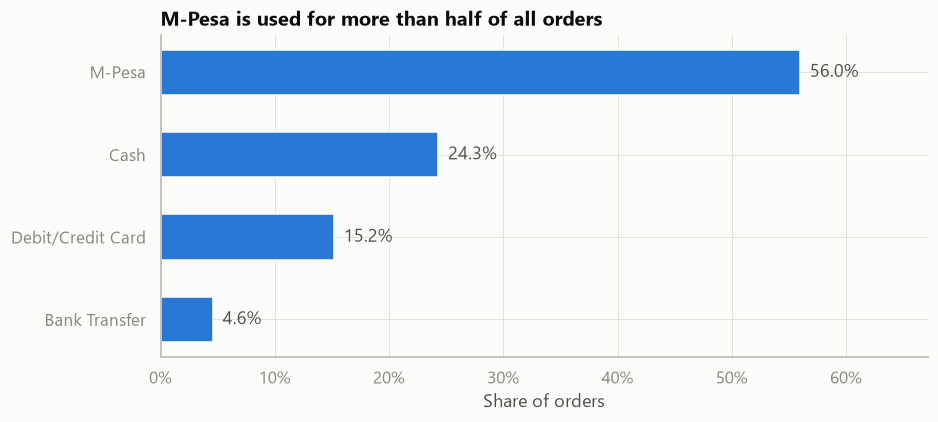

method,Bank Transfer,Cash,Debit/Credit Card,M-Pesa
basket_band,,,,
< KES 500,0.02,0.27,0.12,0.59
KES 500-10K,0.08,0.20,0.20,0.52
KES 10K+,0.17,0.00,0.33,0.50


In [7]:
from matplotlib.ticker import PercentFormatter

pay = sales.drop_duplicates("order_id")["payment_method"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(pay.index[::-1], pay.values[::-1], color=style.HIGHLIGHT, height=0.55)
for y, v in enumerate(pay.values[::-1]):
    ax.text(v, y, f"  {v:.1%}", va="center", color=style.INK["secondary"])
ax.set_xlim(0, pay.max() * 1.2)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("M-Pesa is used for more than half of all orders")
ax.set_xlabel("Share of orders")
style.save(fig, "m1_payment_share")
plt.show()

# Payment mix by basket size confirms the designed relationship
orders_pay = sales.groupby("order_id").agg(value=("total_amount", "sum"), method=("payment_method", "first"))
orders_pay["basket_band"] = pd.cut(orders_pay["value"], [0, 500, 10_000, np.inf],
                                   labels=["< KES 500", "KES 500-10K", "KES 10K+"])
pd.crosstab(orders_pay["basket_band"], orders_pay["method"], normalize="index").round(3)

**Interpretation:** M-Pesa accounts for about 56% of orders, cash about 24%, card about 15% and bank transfer about 5%.
The table shows that the mix depends on basket size. Cash has its biggest share in baskets under KES 500 (27%) and
almost none above KES 10,000. In those big baskets, card (33%) and bank transfer (17%) take a much larger share.

**Business implication:** M-Pesa till uptime is business-critical. Card and bank options matter most for high-value
electronics sales.

### 3.4 Customer purchase frequency

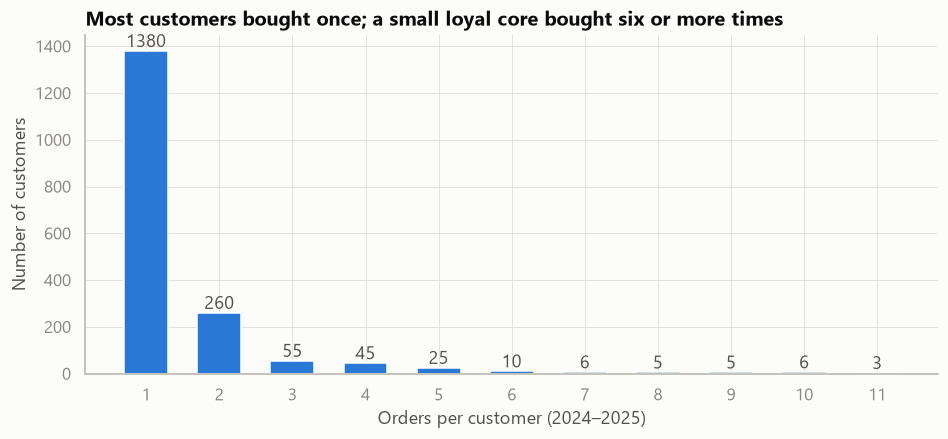

Repeat customers: 23.3%
Revenue share of the top 10% of customers: 43.3%


In [8]:
orders_per_customer = sales.groupby("customer_id")["order_id"].nunique()
freq = orders_per_customer.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(freq.index.astype(str), freq.values, color=style.HIGHLIGHT, width=0.6)
for x, v in enumerate(freq.values):
    ax.text(x, v, f"{v}", ha="center", va="bottom", color=style.INK["secondary"])
ax.set_title("Most customers bought once; a small loyal core bought six or more times")
ax.set_xlabel("Orders per customer (2024–2025)")
ax.set_ylabel("Number of customers")
style.save(fig, "m1_orders_per_customer")
plt.show()

repeat_share = (orders_per_customer >= 2).mean()
top10_share = (sales.groupby("customer_id")["total_amount"].sum()
               .sort_values(ascending=False).head(int(0.10 * len(orders_per_customer))).sum()
               / sales["total_amount"].sum())
print(f"Repeat customers: {repeat_share:.1%}")
print(f"Revenue share of the top 10% of customers: {top10_share:.1%}")

**Interpretation:** about 77% of customers bought only once in two years, and about 23% came back. A small group made
six or more orders. Spending is concentrated: the top 10% of customers bring in about **43%** of revenue.

**Business implication:** keeping the small repeat-buying core is worth much more per customer than acquiring
one-off shoppers. This is the motivation for the RFM and at-risk analyses (Milestones 4 and 6). It also warns us that
churn modelling will rest on a limited number of repeat customers.

### 3.5 Weekly pattern

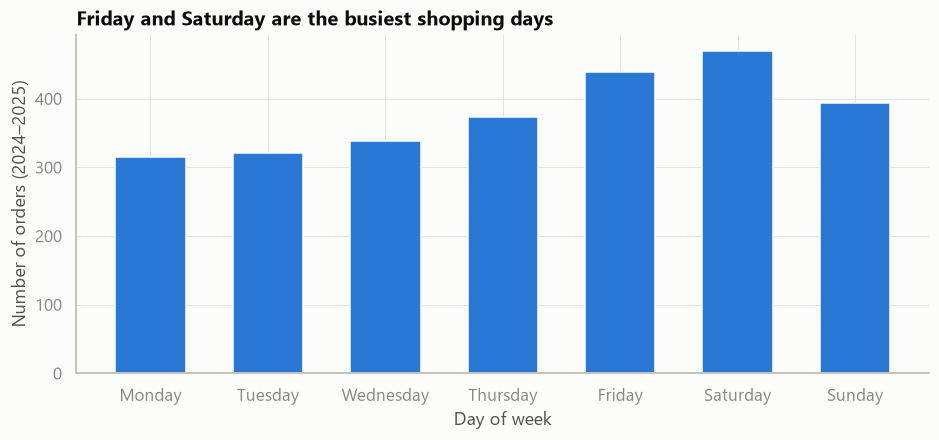

In [9]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = (sales.drop_duplicates("order_id")["transaction_date"].dt.day_name()
          .value_counts().reindex(weekday_order))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_day.index, by_day.values, color=style.HIGHLIGHT, width=0.6)
ax.set_title("Friday and Saturday are the busiest shopping days")
ax.set_xlabel("Day of week")
ax.set_ylabel("Number of orders (2024–2025)")
style.save(fig, "m1_orders_by_weekday")
plt.show()

**Interpretation:** Saturday is the busiest day, followed by Friday and Sunday. Monday and Tuesday are the quietest.

**Business implication:** weekend staffing and shelf replenishment on Friday are justified. Midweek is the natural
window for deliveries and stock counts.

## 4. Injected data-quality issues (for Milestone 2)

The raw files contain a small, controlled set of realistic problems. Each one is logged in
`docs/dq_injection_log.csv` together with its **original value**.

**Important:** Milestone 2 must detect these problems *independently*. The log is opened only at the end, as an audit.

In [10]:
log = pd.read_csv(config.DOCS_DIR / "dq_injection_log.csv")
issue_summary = (log.groupby(["table", "issue_type"]).size()
                 .rename("records_affected").reset_index())
display(issue_summary)
print(f"Total logged changes: {len(log)}  "
      f"(sales rows touched: {log.loc[log.table == 'sales_transactions', 'record_key'].nunique()} of 3,000)")

,table,issue_type,records_affected
0,customers,inconsistent_label,8
1,products,inconsistent_label,2
2,sales_transactions,calculation_mismatch,6
3,sales_transactions,duplicate_row,12
4,sales_transactions,inconsistent_date_format,15
5,sales_transactions,inconsistent_label,30
6,sales_transactions,missing_value,35
7,sales_transactions,numeric_stored_as_text,10
8,sales_transactions,outlier_entry_error,4
9,sales_transactions,price_typo,3


Total logged changes: 126  (sales rows touched: 115 of 3,000)


In [11]:
# Evidence that the problems are visible in the raw file
print("Raw dtypes that are wrong because of injected text values:")
print(raw_sales.dtypes[["transaction_date", "total_amount"]].to_string())
print("\nExact duplicate rows:", raw_sales.duplicated().sum())
print("\nPayment method labels found in raw data:")
print(raw_sales["payment_method"].value_counts(dropna=False).to_string())

Raw dtypes that are wrong because of injected text values:
transaction_date    str
total_amount        str

Exact duplicate rows: 12

Payment method labels found in raw data:
payment_method
M-Pesa               1633
Cash                  696
Debit/Credit Card     476
Bank Transfer         155
NaN                    10
M-PESA                  7
mpesa                   6
m-pesa                  4
CASH                    4
credit card             3
MPESA                   2
 Cash                   1
Bank                    1
card                    1
cash                    1


| Issue | Why it is realistic | Expected fix in Milestone 2 |
|---|---|---|
| 12 duplicate rows | A receipt was submitted twice | Remove exact duplicates |
| 25 missing `customer_id` | Loyalty card not scanned | Keep for revenue; flag as walk-in; exclude from customer analytics |
| 10 missing `payment_method` | Till did not record the tender type | Label as "Unknown" (do not guess) |
| 30 inconsistent payment labels | Manual entry at different tills | Map to 4 standard labels |
| 15 dates in `dd/mm/yyyy` format | Export from an older till | Parse with the explicit format |
| 10 amounts stored as text ("KES 1,234.00") | Formatted export | Strip text and convert to a number |
| 4 quantities of 999 | Keying error | Detect because quantity × price does not match the total; restore the quantity |
| 3 unit prices 10× too high | Extra zero typed | Detect by comparing with the catalogue price |
| 6 totals with the discount missing | Calculation bug | Recalculate from the formula |
| Category, county and gender label variants | Inconsistent master data | Standardize |

Two **genuine** bulk purchases (60 bottled waters and 48 bags of sugar) are real outliers. They must be investigated
and *kept*, which shows that outliers are not removed automatically.

## 5. Summary

- ✅ Exactly 3,000 raw sales rows; 6 related tables plus 1 verified public dataset
- ✅ Reproducible from seed 2024
- ✅ Designed patterns confirmed: December peak, January dip, weekend peak, category margins, M-Pesa dominance, concentrated customer value
- ✅ 126 logged quality issues ready for Milestone 2